In [1]:
#| label: import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

## Solution 1: PDP and ICE in case of interactions

In [2]:
#| label: ice-pdp
def ice(f, X, j, grid):
    """ICE matrix: one curve per row (observation), one column per grid value.

    f: prediction function | X: np.array (n, p) | j: feature index | grid: g values
    """
    curves = np.empty((X.shape[0], len(grid)))
    for g_id, val in enumerate(grid):
        X_rep = X.copy()
        X_rep[:, j] = val                       # grid sweep on column j
        curves[:, g_id] = f(X_rep[:, 0], X_rep[:, 1])  # vectorised call
    return curves


def pdp(f, X, j, grid):
    return ice(f, X, j, grid).mean(axis=0)

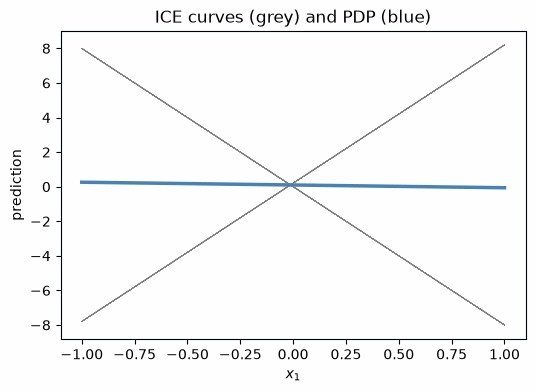

In [3]:
#| label: ice-pdp-example
# linear model with known coefficients (Exercise 1 b)
def f_hat(x1, x2, beta0=0, beta1=-8, beta2=0.2, beta3=16):
    return beta0 + beta1 * x1 + beta2 * x2 + beta3 * x1 * x2


rng = np.random.default_rng(42)
n = 100
X = np.column_stack([
    rng.uniform(-1, 1, n),       # Unif(-1,1)
    rng.binomial(1, 0.5, n),     # Bernoulli(0.5)
]).astype(float)
grid = np.arange(-1, 1.01, 0.25)  # evaluation grid for x1

ICE = ice(f_hat, X, 0, grid)
PDP = pdp(f_hat, X, 0, grid)

fig, ax = plt.subplots(figsize=(6, 4))
for curve in ICE:
    ax.plot(grid, curve, color="grey", linewidth=0.3, alpha=0.6)
ax.plot(grid, PDP, color="steelblue", linewidth=2.5)
ax.set_title("ICE curves (grey) and PDP (blue)")
ax.set_xlabel("$x_1$")
ax.set_ylabel("prediction")
plt.show()

In [4]:
#| label: c-ice-pdp
def c_ice(f, X, j, grid, ref=0):
    """Centered ICE: subtract each curve's value at the reference grid index
    (0-based in Python)."""
    M = ice(f, X, j, grid)
    return M - M[:, [ref]]


def c_pdp(f, X, j, grid, ref=0):
    return c_ice(f, X, j, grid, ref=ref).mean(axis=0)

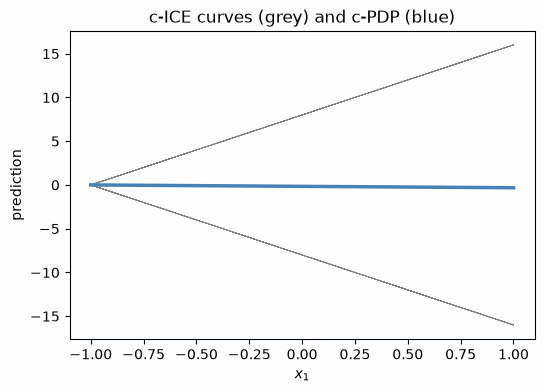

In [5]:
#| label: c-ice-pdp-example
ref = int(np.argmin(grid))
cICE = c_ice(f_hat, X, 0, grid, ref=ref)
cPDP = c_pdp(f_hat, X, 0, grid, ref=ref)

fig, ax = plt.subplots(figsize=(6, 4))
for curve in cICE:
    ax.plot(grid, curve, color="grey", linewidth=0.3, alpha=0.6)
ax.plot(grid, cPDP, color="steelblue", linewidth=2.5)
ax.set_title("c-ICE curves (grey) and c-PDP (blue)")
ax.set_xlabel("$x_1$")
ax.set_ylabel("prediction")
plt.show()

## Solution 2: Derivative, Forward, and Non-Linearity Effects

In [6]:
#| label: dme-fme-nlm
def dME(f, x, j, h=1e-5):
    """Central difference approximation of the derivative marginal effect."""
    x_forward = np.array(x, dtype=float)
    x_backward = np.array(x, dtype=float)
    x_forward[j] += h
    x_backward[j] -= h
    return (f(*x_forward) - f(*x_backward)) / (2 * h)


def fME(f, x, h_vec):
    """Forward marginal effect with a vector of stepsizes."""
    x = np.array(x, dtype=float)
    x_perturbed = x + np.array(h_vec, dtype=float)
    return f(*x_perturbed) - f(*x)


def NLM(f, x, h_vec, t_vals=np.linspace(0.1, 0.9, 9)):
    """Non-Linearity Measure (R^2 of the secant along the path)."""
    x = np.array(x, dtype=float)
    h_vec = np.array(h_vec, dtype=float)
    f_vals = np.array([f(*(x + t * h_vec)) for t in t_vals])
    f_bar = f_vals.mean()
    fme_val = fME(f, x, h_vec)
    g_vals = np.array([f(*x) + t * fme_val for t in t_vals])
    return 1 - np.sum((f_vals - g_vals) ** 2) / np.sum((f_vals - f_bar) ** 2)

In [7]:
#| label: dme-fme-nlm-check
# model of Exercise 2
def f_hat(x1, x2, theta0=0, theta1=1, theta2=0.5, theta12=2):
    return theta0 + theta1 * x1**2 + theta2 * x2**2 + theta12 * x1 * x2


x = (1, 2)

print("dME_1(1, 2)         =", dME(f_hat, x, j=0))
print("fME_1(1, 2; h = 1)  =", fME(f_hat, x, h_vec=[1, 0]))
print("fME_1(1, 2; h = 0.5)=", fME(f_hat, x, h_vec=[0.5, 0]))
print("NLM (h = 0.5)       =", NLM(f_hat, x, h_vec=[0.5, 0]))

dME_1(1, 2)         = 5.999999999994897
fME_1(1, 2; h = 1)  = 7.0
fME_1(1, 2; h = 0.5)= 3.25
NLM (h = 0.5)       = 0.9967140158610599


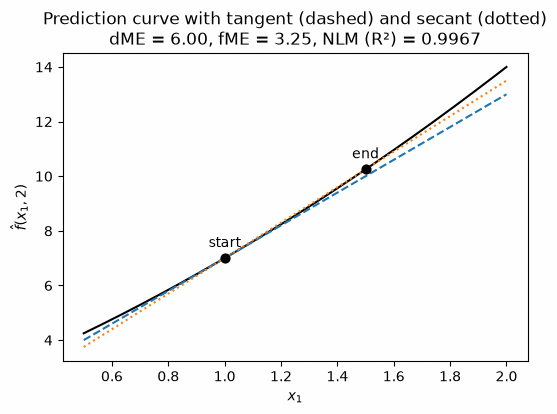

In [8]:
#| label: dme-fme-plot
h1 = 0.5
dme_val = dME(f_hat, x, j=0)
fme_val = fME(f_hat, x, h_vec=[h1, 0])
nlm_val = NLM(f_hat, x, h_vec=[h1, 0])

# prediction curve in the neighbourhood of x1
x_seq = np.linspace(x[0] - 0.5, x[0] + h1 + 0.5, 400)
y_curve = f_hat(x_seq, x[1])

# tangent (dashed) and secant (dotted)
y_tan = f_hat(*x) + dme_val * (x_seq - x[0])
y_sec = f_hat(*x) + fme_val / h1 * (x_seq - x[0])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_seq, y_curve, color="black", linewidth=1.5)
ax.plot(x_seq, y_tan, linestyle="dashed", color="tab:blue")
ax.plot(x_seq, y_sec, linestyle="dotted", color="tab:orange")
pts_x = [x[0], x[0] + h1]
pts_y = [f_hat(*x), f_hat(x[0] + h1, x[1])]
ax.scatter(pts_x, pts_y, s=40, color="black", zorder=3)
for px, py, lbl in zip(pts_x, pts_y, ["start", "end"]):
    ax.annotate(lbl, (px, py), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Prediction curve with tangent (dashed) and secant (dotted)\n"
             f"dME = {dme_val:.2f}, fME = {fme_val:.2f}, NLM (R\u00b2) = {nlm_val:.4f}")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$\\hat{f}(x_1, 2)$")
plt.show()

## Solution 3: ALE

In [9]:
#| label: ale-data
# wheat seeds data: predict the (normalized) Type from the numeric features
df = pd.read_csv("../data/wheat_seeds.csv").dropna()
y = (df["Type"] - df["Type"].min()) / (df["Type"].max() - df["Type"].min())
X = df.drop(columns="Type").to_numpy()
feature_names = list(df.drop(columns="Type").columns)

# fit a random forest on a 70% training split
rng = np.random.default_rng(42)
train = rng.choice(len(X), size=int(0.7 * len(X)), replace=False)
model = RandomForestRegressor(random_state=42).fit(X[train], y.to_numpy()[train])

In [10]:
#| label: get-bounds
def get_bounds(X, s, n_intervals=100):
    """
    Calculates interval bounds given a X's min and max values.
    Only values in the s-th column are considered.

    Parameters:
        X (np.array with shape (num_instances, num_features)): Input data.
        s (int): Index of the feature x_s.
        n_intervals (int): Number of intervals.

    Returns:
        bounds (list): Values of bounds with `n_intervals`+1 entries.
    """
    x_s = X[:, s]
    x_s_min = np.min(x_s)
    x_s_max = np.max(x_s)
    bounds = list(np.linspace(x_s_min, x_s_max, n_intervals + 1))

    return bounds


# bounds of 4 intervals for the first feature (Area)
print(get_bounds(X, 0, n_intervals=4))

[np.float64(10.59), np.float64(13.2375), np.float64(15.885), np.float64(18.5325), np.float64(21.18)]


In [11]:
#| label: calculate-ale
def calculate_ale(model, X, s, n_intervals=100, centered=False):
    """
    Compute the accumulated local effect of a numeric continuous feature.

    Parameters:
        model: Model which has a predict method.
        X (np.array with shape (num_instances, num_features)): Input data.
        s (int): Index of the feature x_s.
        n_intervals (int): How many intervals should be used.
        centered (bool): Whether to return uncentered or centered ALE.

    Returns:
        bounds (list): See function `get_bounds`.
        ale (list with `n_intervals` entries): Values of ALE.
    """
    x_s = X[:, s]
    bounds = get_bounds(X, s, n_intervals)

    uncentered_ale = []

    # i1 = z_{k-1}
    # i2 = z_k
    for i1, i2 in zip(bounds, bounds[1:]):
        # Get ids in between the interval
        if i1 == bounds[0]:
            # Make sure to include the point on the first interval too
            idx = np.where((x_s >= i1) & (x_s <= i2))[0]
        else:
            idx = np.where((x_s > i1) & (x_s <= i2))[0]

        if len(idx) == 0:
            uncentered_ale.append(0)
            continue

        # Now we replace the values at position s one time with the smallest value
        # and one time with the highest value in this interval.
        X_min = X[idx, :]
        X_max = X[idx, :]
        X_min[:, s] = i1
        X_max[:, s] = i2

        # And get the new predictions
        y_min = model.predict(X_min)
        y_max = model.predict(X_max)

        # Calculate difference now
        diff = y_max - y_min
        uncentered_ale_k = np.sum(diff) / len(idx)
        uncentered_ale.append(uncentered_ale_k)

    # Now accumulate
    uncentered_ale = np.cumsum(uncentered_ale)

    if centered:
        # Center ALE here
        mean_uncentered_ale = np.sum(uncentered_ale) / len(uncentered_ale)
        centered_ale = [ale_k - mean_uncentered_ale for ale_k in uncentered_ale]

        return bounds, centered_ale
    else:
        return bounds, uncentered_ale


# uncentered ALE of the first feature with 4 intervals
bounds, ale = calculate_ale(model, X, 0, n_intervals=4)
print("bounds:", np.round(bounds, 3))
print("ALE:   ", np.round(ale, 4))

bounds: [10.59  13.238 15.885 18.532 21.18 ]
ALE:    [0.0112 0.1463 0.1647 0.1647]


In [12]:
#| label: prepare-ale
def prepare_ale(model, X, s, n_intervals=100, centered=False):
    """
    Uses `calculate_ale` to prepare x and y data, which can be used
    by matplotlib directly.

    Parameters:
        model: Model which has a predict method.
        X (np.array with shape (num_instances, num_features)): Input data.
        s (int): Index of the feature x_s.
        n_intervals (int): How many intervals should be used.
        centered (bool): Whether to return uncentered or centered ALE.

    Returns:
        x (list or 1D np.ndarray): Centers of two bounds. `n_intervals` entries.
        y (list or 1D np.ndarray): ALE values. `n_intervals` entries.
    """
    bounds, y = calculate_ale(model, X, s, n_intervals, centered)
    x = [(i1 + i2) / 2 for i1, i2 in zip(bounds, bounds[1:])]

    return x, y

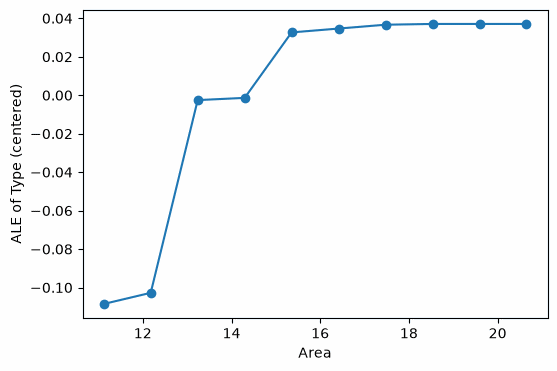

In [13]:
#| label: ale-plot
x_ale, y_ale = prepare_ale(model, X, 0, n_intervals=10, centered=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x_ale, y_ale, marker="o")
ax.set_xlabel("Area")
ax.set_ylabel("ALE of Type (centered)")
plt.show()

## Solution 4: Categorical ALE

In [14]:
#| label: catale-given
credit = pd.read_csv("../data/credit.csv")


def order_levels(data, feature_name):
    """
    Orders levels of a nominal scaled feature according to other features in a dataset.

    Parameters:
        data (pd.DataFrame): Input data.
        feature_name (str): Name of the categorical feature which should be ordered.

    Returns: np.array (str) of ordered class labels
    """
    feature = data[feature_name].values
    others = list(data.columns)
    others.remove(feature_name)
    feature_lev = np.unique(feature)

    dists = []

    # Iterate over other features, sum up distances
    for i in range(len(others)):
        k = others[i]
        feature_k = data[k].values
        if (feature_k.dtype.kind != 'i') & (feature_k.dtype.kind != 'f'):
            ds = get_diff_cat(feature_k, feature)
        else:
            ds = get_diff_numeric(feature_k, feature)

        if i == 0:
            dists = ds
        else:
            dists['dist'] = dists['dist'] + ds['dist']

    # Create a matrix of distances
    dists = dists.pivot(index='class1', columns='class2', values='dist')

    # conduct classical multi-dimensional scaling (principal coordinates
    # analysis, like R's cmdscale): double-center the squared distance
    # matrix and project on the first principal coordinate
    D2 = np.asarray(dists, dtype=float) ** 2
    J = np.eye(len(D2)) - np.ones_like(D2) / len(D2)
    B = -0.5 * J @ D2 @ J
    eigval, eigvec = np.linalg.eigh(B)
    scaled = eigvec[:, -1] * np.sqrt(max(eigval[-1], 0))

    order = feature_lev[scaled.argsort()]

    return order


def get_diff_numeric(feature_k, feature_j):
    """
    Calculates the pairwise distances of classes of j of a numeric feature k.

    Parameters:
        feature_k (np.array): Values of the numeric feature.
        feature_j (np.array): Values of the categorical feature for which
            similarity based on feature k should be assessed.

    Returns: pd.DataFrame with three columns:
        class1: name of the first class
        class2: name of the second class
        dist: the distributional distance between the two classes for feature k
    """
    # set up data.frame which we will fill later
    feature_lev = np.unique(feature_j)
    param_grid = {'class1': feature_lev, 'class2': feature_lev}
    dists = pd.DataFrame(ParameterGrid(param_grid))

    # get decentiles
    quants = np.quantile(feature_k, q=np.linspace(0, 1, num=10))

    # derive empirical distribution function for each category
    ecdfs = {}
    for lev in feature_lev:
        ecdfs[lev] = sm.distributions.ECDF(feature_k[feature_j == lev])(quants)

    # get pairwise absolute maximum distances of the empirical
    # distribution functions between the different categories
    ecdf_dists = []
    for i1, i2 in zip(dists.class1.values, dists.class2.values):
        ecdf_dists.append(max(abs(ecdfs[i1] - ecdfs[i2])))

    dists["dist"] = ecdf_dists
    return dists

In [15]:
#| label: get-diff-cat
def get_diff_cat(feature_k, feature_j):
    """
    Calculates the pairwise distances of classes of j of a categorical feature k.

    Parameters:
        feature_k (np.array): Values of the categorical feature for which
            relative frequencies per class are calculated.
        feature_j (np.array): Values of the categorical feature for which
            similarity based on feature k should be assessed.

    Returns: pd.DataFrame with three columns:
        class1: name of the first class
        class2: name of the second class
        dist: the distributional distance between the two classes for feature k
    """
    # set up data.frame which we will fill later
    feature_lev = np.unique(feature_j)
    param_grid = {'class1': feature_lev, 'class2': feature_lev}
    dists = pd.DataFrame(ParameterGrid(param_grid))

    # get relative frequency table
    xcount = np.unique(feature_j, return_counts=True)[1]
    A = pd.crosstab(feature_k, feature_j) / xcount

    # compute pairwise absolute distances
    ecdf_dists = []
    for i1, i2 in zip(dists.class1.values, dists.class2.values):
        ecdf_dists.append(sum(abs(A[i1] - A[i2])))
    dists["dist"] = ecdf_dists

    return dists

In [16]:
#| label: get-diff-cat-example
get_diff_cat(feature_k=credit["employment_duration"].values,
             feature_j=credit["personal_status_sex"].values)

,class1,class2,dist
0,female : non-single or male : single,female : non-single or male : single,0.000000
1,female : non-single or male : single,female : single,0.158626
2,female : non-single or male : single,male : divorced/separated,0.286452
3,female : non-single or male : single,male : married/widowed,0.448293
4,female : single,female : non-single or male : single,0.158626
5,female : single,female : single,0.000000
6,female : single,male : divorced/separated,0.292174
7,female : single,male : married/widowed,0.497620
8,male : divorced/separated,female : non-single or male : single,0.286452
9,male : divorced/separated,female : single,0.292174


In [17]:
#| label: order-levels-example
order_levels(credit, "personal_status_sex")

array(['male : divorced/separated', 'male : married/widowed',
       'female : non-single or male : single', 'female : single'],
      dtype=object)